In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score, roc_curve, matthews_corrcoef
from xgboost import XGBClassifier
from skbio.stats.composition import clr as skbio_clr

warnings.filterwarnings('ignore')

TAX_PATH      = '/srv/common/microbime_data/tax.csv'
PATH_PATH     = '/srv/common/microbime_data/path.csv'
METADATA_PATH = '/srv/common/microbime_data/metadata.csv'
OUTPUT_DIR    = './output_cv_roc'
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTER_FOLDS    = 5
INNER_FOLDS    = 3
RANDOM_STATE   = 42
CLR_PSEUDO     = 1e-6
MIN_PREVALENCE = 0.10
MIN_BIOPROJECTS = 3
FPR_GRID       = np.linspace(0, 1, 200)

CONFIGS = [
    {'task': 'K05', 'feature_set': 'TAX',      'transform': 'CLR',      'model': 'LR_Ridge'},
    {'task': 'K05', 'feature_set': 'TAX+PATH', 'transform': 'CLR',      'model': 'LR_Ridge'},
    {'task': 'K05', 'feature_set': 'PATH',     'transform': 'CLR',      'model': 'LR_Ridge'},
    {'task': 'K02', 'feature_set': 'TAX',      'transform': 'rank.std', 'model': 'XGBoost'},
    {'task': 'K02', 'feature_set': 'TAX+PATH', 'transform': 'CLR',      'model': 'RF'},
    {'task': 'K02', 'feature_set': 'PATH',     'transform': 'CLR',      'model': 'RF'},
]

PARAM_GRIDS = {
    'LR_Ridge': {'C': [0.001, 0.01, 0.1, 1, 10, 100]},
    'XGBoost':  {
        'n_estimators':     [100, 300],
        'max_depth':        [3, 5],
        'learning_rate':    [0.01, 0.1],
        'subsample':        [0.7, 1.0],
        'colsample_bytree': [0.7, 1.0],
    },
    'RF': {
        'n_estimators': [100, 300, 500],
        'max_depth':    [None, 5, 10],
        'max_features': ['sqrt', 0.3],
    },
}

In [2]:
def prevalence_bioproject_filter(X, bioproject):
    present    = X > 0
    prevalence = present.mean(axis=0)
    n_bp       = np.array([
        len(np.unique(bioproject[present[:, j]])) if present[:, j].any() else 0
        for j in range(X.shape[1])
    ])
    return (prevalence >= MIN_PREVALENCE) & (n_bp >= MIN_BIOPROJECTS)


def to_relative(X):
    row_sums = X.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1.0
    return X / row_sums


def apply_clr(X):
    return skbio_clr(X + CLR_PSEUDO)


def apply_clr_blocks(X, n_tax):
    return np.concatenate([
        apply_clr(X[:, :n_tax]),
        apply_clr(to_relative(X[:, n_tax:]))
    ], axis=1)


def rank_std_fit(X_train):
    ranked = np.apply_along_axis(
        lambda row: rankdata(row, method='average'), axis=1, arr=X_train
    )
    mu  = ranked.mean(axis=0)
    std = ranked.std(axis=0)
    std[std == 0] = 1.0
    return mu, std


def rank_std_transform(X, mu, std):
    ranked = np.apply_along_axis(
        lambda row: rankdata(row, method='average'), axis=1, arr=X
    )
    return (ranked - mu) / std


def transform_fold(X_tr, X_te, transform_name, feature_set, n_tax=None):
    if transform_name == 'CLR':
        if feature_set == 'TAX+PATH':
            return apply_clr_blocks(X_tr, n_tax), apply_clr_blocks(X_te, n_tax)
        elif feature_set == 'PATH':
            return apply_clr(to_relative(X_tr)), apply_clr(to_relative(X_te))
        else:
            return apply_clr(X_tr), apply_clr(X_te)
    if transform_name == 'rank.std':
        mu, std = rank_std_fit(X_tr)
        return rank_std_transform(X_tr, mu, std), rank_std_transform(X_te, mu, std)
    raise ValueError(f'Unknown transform: {transform_name}')


def get_model(model_name):
    if model_name == 'LR_Ridge':
        return LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000, random_state=RANDOM_STATE)
    if model_name == 'XGBoost':
        return XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE, verbosity=0, n_jobs=-1)
    if model_name == 'RF':
        return RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
    raise ValueError(f'Unknown model: {model_name}')


def tune_and_predict(X_tr, y_tr, X_te, model_name):
    if len(np.unique(y_tr)) < 2:
        return np.full(len(X_te), 0.5), get_model(model_name)
    model = get_model(model_name)
    grid  = PARAM_GRIDS.get(model_name, {})
    n_pos, n_neg = int(y_tr.sum()), int((y_tr == 0).sum())
    if grid and n_pos >= INNER_FOLDS and n_neg >= INNER_FOLDS:
        inner_cv = StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
        gs = GridSearchCV(model, grid, cv=inner_cv, scoring='roc_auc', refit=True, n_jobs=-1)
        gs.fit(X_tr, y_tr)
        print(f'      best params: {gs.best_params_}  inner AUC={gs.best_score_:.4f}')
        return gs.best_estimator_.predict_proba(X_te)[:, 1], gs.best_estimator_
    else:
        model.fit(X_tr, y_tr)
        return model.predict_proba(X_te)[:, 1], model


def compute_metrics(y_true, probs):
    if len(np.unique(y_true)) < 2:
        return None, None
    auc  = roc_auc_score(y_true, probs)
    mcc  = matthews_corrcoef(y_true, (probs >= 0.5).astype(int))
    return auc, mcc

In [3]:
print('Loading data...')
meta = pd.read_csv(METADATA_PATH)
tax  = pd.read_csv(TAX_PATH)
path = pd.read_csv(PATH_PATH)

df = meta.merge(tax, on='run').merge(path, on='run')

tax_cols  = [c for c in tax.columns  if c != 'run']
path_cols = [c for c in path.columns if c != 'run']

X_tax_raw  = df[tax_cols].values.astype(float)
X_path_raw = df[path_cols].values.astype(float)

y_k05      = df['K05_gingivitis_periodontitis'].values.astype(int)
y_k02      = df['K02_caries'].values.astype(int)
healthy    = df['healthy'].values.astype(bool)
bioproject = df['bioproject'].values.astype(str)

print(f'Total samples : {len(df)}')
print(f'K05=1         : {y_k05.sum()}   healthy: {healthy.sum()}')
print(f'K02=1         : {y_k02.sum()}')
print(f'TAX features  : {len(tax_cols)}   PATH features: {len(path_cols)}')

Loading data...
Total samples : 558
K05=1         : 161   healthy: 223
K02=1         : 205
TAX features  : 719   PATH features: 522


In [ ]:
all_results = []

for cfg in CONFIGS:
    task        = cfg['task']
    feature_set = cfg['feature_set']
    transform   = cfg['transform']
    model_name  = cfg['model']
    cfg_name    = f"{task} | {feature_set} | {transform} | {model_name}"

    print(f'\n{"="*65}')
    print(f'Config: {cfg_name}')

    y          = y_k05 if task == 'K05' else y_k02
    is_disease = y.astype(bool)
    strat_label = np.array([f'{bp}_{yi}' for bp, yi in zip(bioproject, y)])

    fold_aucs_all  = []
    fold_aucs_hlth = []
    fold_mccs      = []
    fold_tprs      = []
    oof_probs      = np.full(len(y), np.nan)
    best_estimators = []

    outer_cv = StratifiedKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=RANDOM_STATE)

    for fold_i, (train_idx, test_idx) in enumerate(outer_cv.split(X_tax_raw, strat_label)):

        train_mask = is_disease[train_idx] | healthy[train_idx]
        tr_idx = train_idx[train_mask]
        te_idx = test_idx

        bp_train = bioproject[tr_idx]

        keep_tax  = prevalence_bioproject_filter(X_tax_raw[tr_idx],  bp_train)
        keep_path = prevalence_bioproject_filter(X_path_raw[tr_idx], bp_train)

        X_tax_tr  = X_tax_raw[tr_idx][:,  keep_tax]
        X_tax_te  = X_tax_raw[te_idx][:,  keep_tax]
        X_path_tr = X_path_raw[tr_idx][:, keep_path]
        X_path_te = X_path_raw[te_idx][:, keep_path]

        n_tax_fold = X_tax_tr.shape[1]

        if feature_set == 'TAX':
            X_tr_raw, X_te_raw = X_tax_tr, X_tax_te
        elif feature_set == 'PATH':
            X_tr_raw, X_te_raw = X_path_tr, X_path_te
        else:
            X_tr_raw = np.concatenate([X_tax_tr, X_path_tr], axis=1)
            X_te_raw = np.concatenate([X_tax_te, X_path_te], axis=1)

        y_tr = y[tr_idx]
        y_te = y[te_idx]

        print(f'\n  Fold {fold_i+1}/{OUTER_FOLDS}  '
              f'train: {len(y_tr)} (pos={y_tr.sum()}, neg={(y_tr==0).sum()})  '
              f'test: {len(y_te)} (pos={y_te.sum()})  '
              f'features after filter: {X_tr_raw.shape[1]}')

        X_tr_t, X_te_t = transform_fold(X_tr_raw, X_te_raw, transform, feature_set, n_tax_fold)
        probs, estimator = tune_and_predict(X_tr_t, y_tr, X_te_t, model_name)
        best_estimators.append(estimator)
        oof_probs[te_idx] = probs

        auc_all, mcc = compute_metrics(y_te, probs)
        if auc_all is not None:
            fold_aucs_all.append(auc_all)
            fold_mccs.append(mcc)
            fpr, tpr, _ = roc_curve(y_te, probs)
            interp_tpr = np.interp(FPR_GRID, fpr, tpr)
            interp_tpr[0] = 0.0
            interp_tpr[-1] = 1.0
            fold_tprs.append(interp_tpr)
            print(f'      AUC (all negatives) = {auc_all:.4f}  MCC = {mcc:.4f}')

        hlth_te_mask = healthy[te_idx] | is_disease[te_idx]
        y_te_hlth    = y_te[hlth_te_mask]
        probs_hlth   = probs[hlth_te_mask]
        auc_hlth, _  = compute_metrics(y_te_hlth, probs_hlth)
        if auc_hlth is not None:
            fold_aucs_hlth.append(auc_hlth)
            print(f'      AUC (vs healthy only) = {auc_hlth:.4f}')

    valid_mask = ~np.isnan(oof_probs)
    oof_auc_all  = roc_auc_score(y[valid_mask], oof_probs[valid_mask]) if valid_mask.any() else np.nan
    oof_mask_hlth = valid_mask & (healthy | is_disease)
    oof_auc_hlth  = roc_auc_score(y[oof_mask_hlth], oof_probs[oof_mask_hlth]) if oof_mask_hlth.sum() > 0 else np.nan

    mean_auc = float(np.mean(fold_aucs_all)) if fold_aucs_all else np.nan
    std_auc  = float(np.std(fold_aucs_all))  if fold_aucs_all else np.nan
    mean_mcc = float(np.mean(fold_mccs))     if fold_mccs     else np.nan
    mean_tpr = np.mean(fold_tprs, axis=0)    if fold_tprs     else np.zeros_like(FPR_GRID)
    std_tpr  = np.std(fold_tprs,  axis=0)    if fold_tprs     else np.zeros_like(FPR_GRID)

    print(f'\n  OOF AUC (all neg): {oof_auc_all:.4f}  OOF AUC (vs healthy): {oof_auc_hlth:.4f}')
    print(f'  mean±std AUC: {mean_auc:.4f}±{std_auc:.4f}  mean MCC: {mean_mcc:.4f}')

    all_results.append({
        'task': task, 'cfg_name': cfg_name,
        'feature_set': feature_set, 'transform': transform, 'model': model_name,
        'oof_auc_all':  round(oof_auc_all, 4),
        'oof_auc_hlth': round(oof_auc_hlth, 4),
        'mean_auc': round(mean_auc, 4), 'std_auc': round(std_auc, 4),
        'mean_mcc': round(mean_mcc, 4),
        'fold_aucs': fold_aucs_all,
        'mean_tpr': mean_tpr, 'std_tpr': std_tpr,
        'y': y, 'oof_probs': oof_probs,
        'best_estimators': best_estimators,
    })

In [5]:
rows = []
for r in all_results:
    rows.append({
        'config':        r['cfg_name'],
        'oof_auc_all':   r['oof_auc_all'],
        'oof_auc_hlth':  r['oof_auc_hlth'],
        'mean_auc':      r['mean_auc'],
        'std_auc':       r['std_auc'],
        'mean_mcc':      r['mean_mcc'],
    })
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
summary.to_csv(os.path.join(OUTPUT_DIR, 'cv_summary.csv'), index=False)

                         config  oof_auc_all  oof_auc_hlth  mean_auc  std_auc  mean_mcc
     K05 | TAX | CLR | LR_Ridge       0.8719        0.9071    0.8777   0.0083    0.5391
K05 | TAX+PATH | CLR | LR_Ridge       0.8798        0.9118    0.8826   0.0028    0.5626
    K05 | PATH | CLR | LR_Ridge       0.8153        0.8262    0.8206   0.0260    0.4864
 K02 | TAX | rank.std | XGBoost       0.7550        0.8318    0.7613   0.0304    0.3549
      K02 | TAX+PATH | CLR | RF       0.7611        0.8327    0.7633   0.0155    0.3691
          K02 | PATH | CLR | RF       0.7330        0.7772    0.7348   0.0364    0.3339


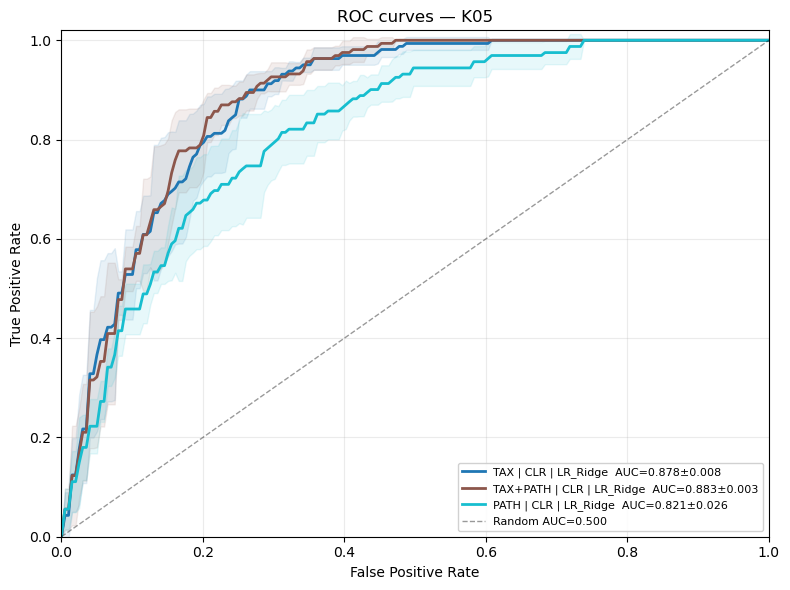

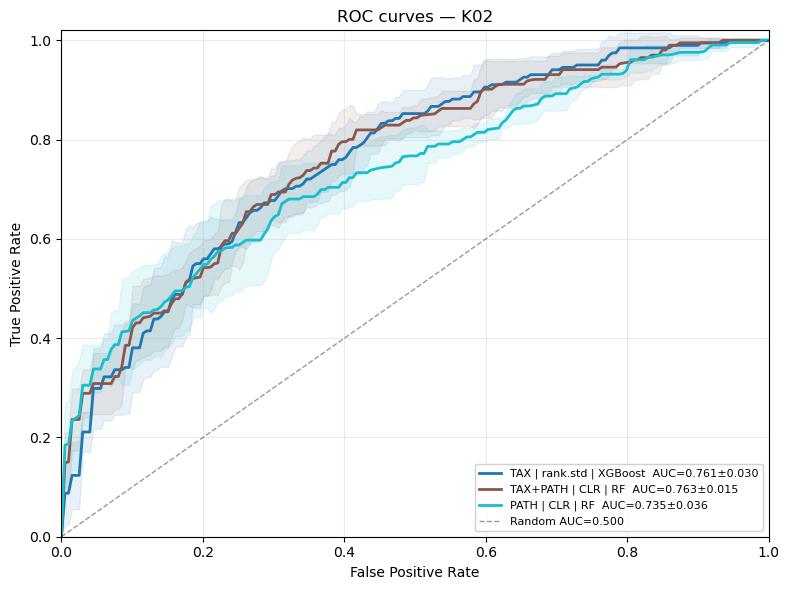

In [6]:
for task in ['K05', 'K02']:
    task_results = [r for r in all_results if r['task'] == task]
    if not task_results:
        continue

    fig, ax = plt.subplots(figsize=(8, 6))
    colors = plt.cm.tab10(np.linspace(0, 1, len(task_results)))

    for r, color in zip(task_results, colors):
        label = f"{r['feature_set']} | {r['transform']} | {r['model']}  AUC={r['mean_auc']:.3f}±{r['std_auc']:.3f}"
        ax.plot(FPR_GRID, r['mean_tpr'], lw=2, color=color, label=label)
        ax.fill_between(FPR_GRID,
                        r['mean_tpr'] - r['std_tpr'],
                        r['mean_tpr'] + r['std_tpr'],
                        alpha=0.10, color=color)

    ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.4, label='Random AUC=0.500')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'ROC curves — {task}')
    ax.legend(loc='lower right', fontsize=8, framealpha=0.9)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.02])
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'roc_{task}.png'), dpi=150, bbox_inches='tight')
    plt.show()


SHAP: K05 | TAX | CLR | LR_Ridge
  SHAP model best params: {'C': 0.001}


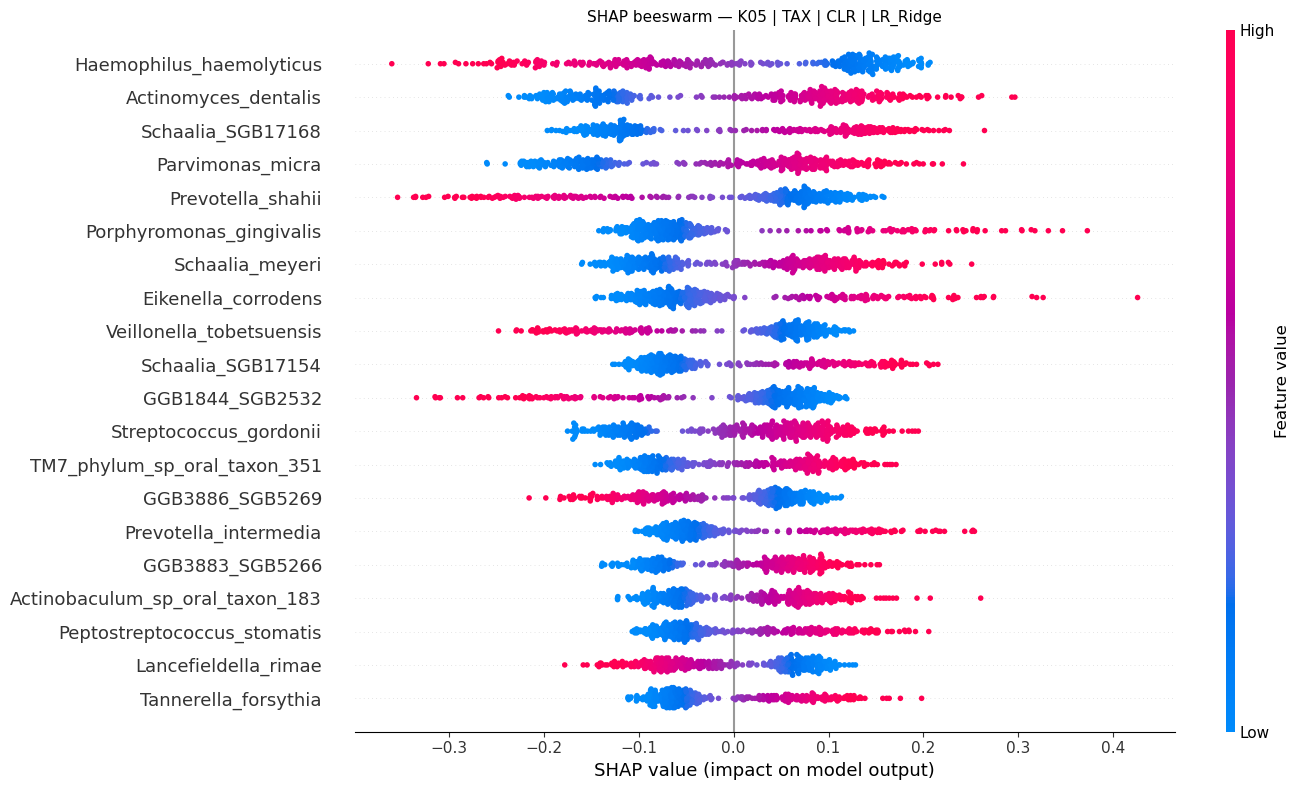


SHAP: K05 | TAX+PATH | CLR | LR_Ridge
  SHAP model best params: {'C': 0.001}


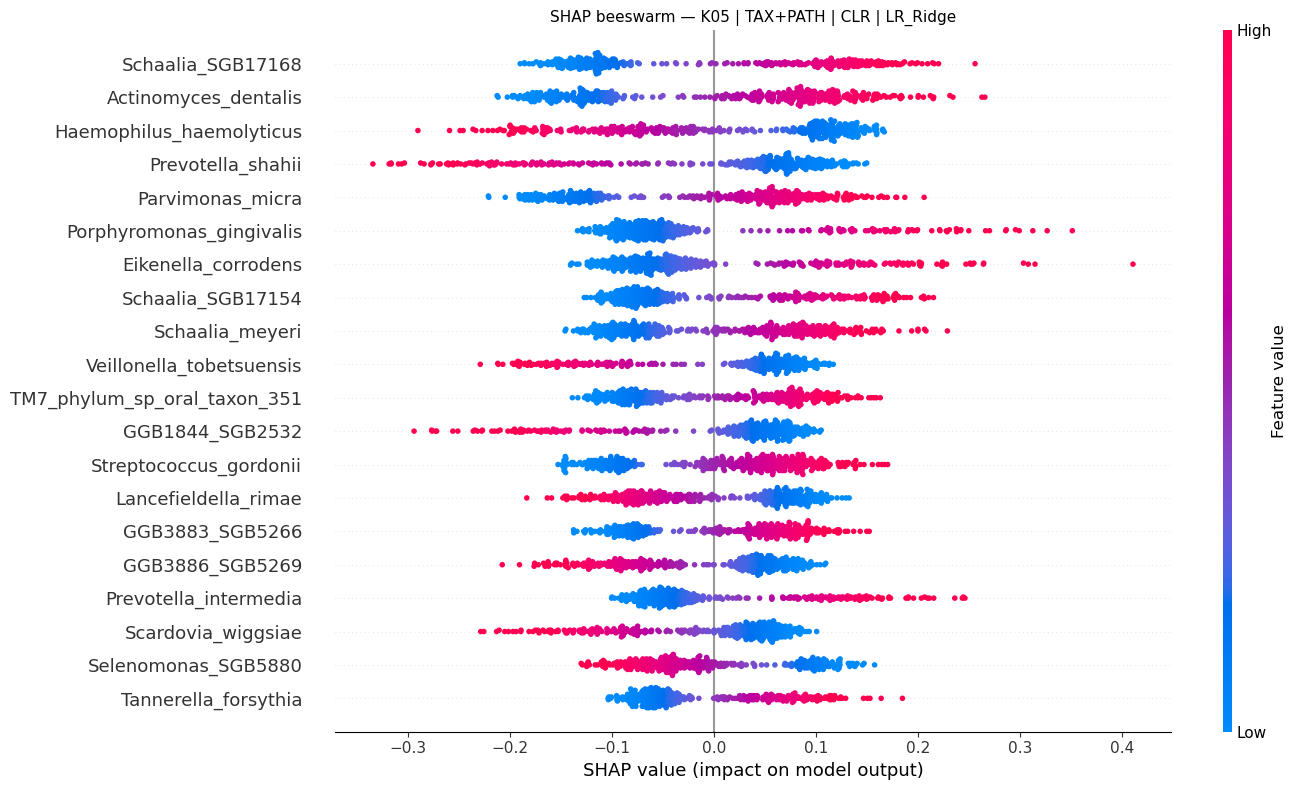


SHAP: K05 | PATH | CLR | LR_Ridge
  SHAP model best params: {'C': 0.01}


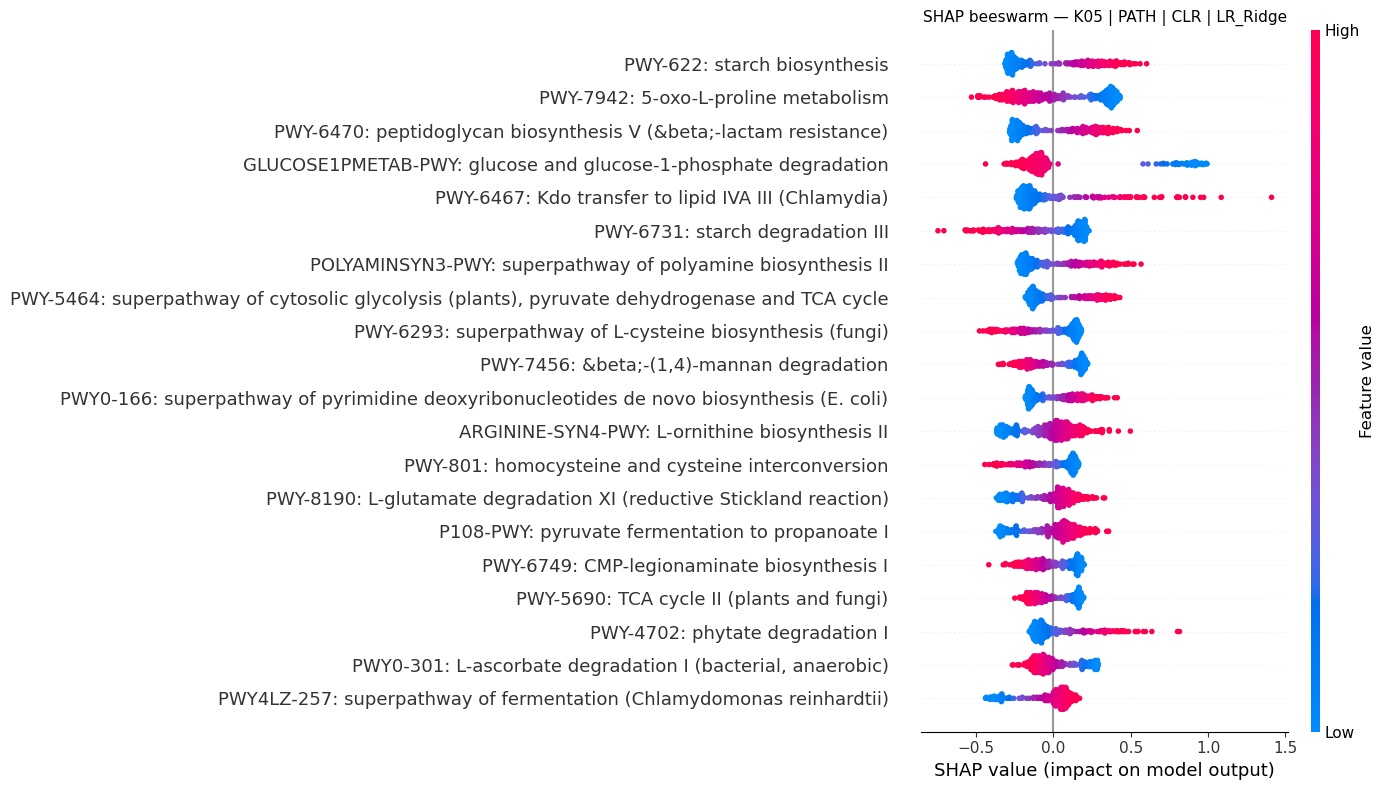


SHAP: K02 | TAX | rank.std | XGBoost
  SHAP model best params: {'colsample_bytree': 0.7, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}


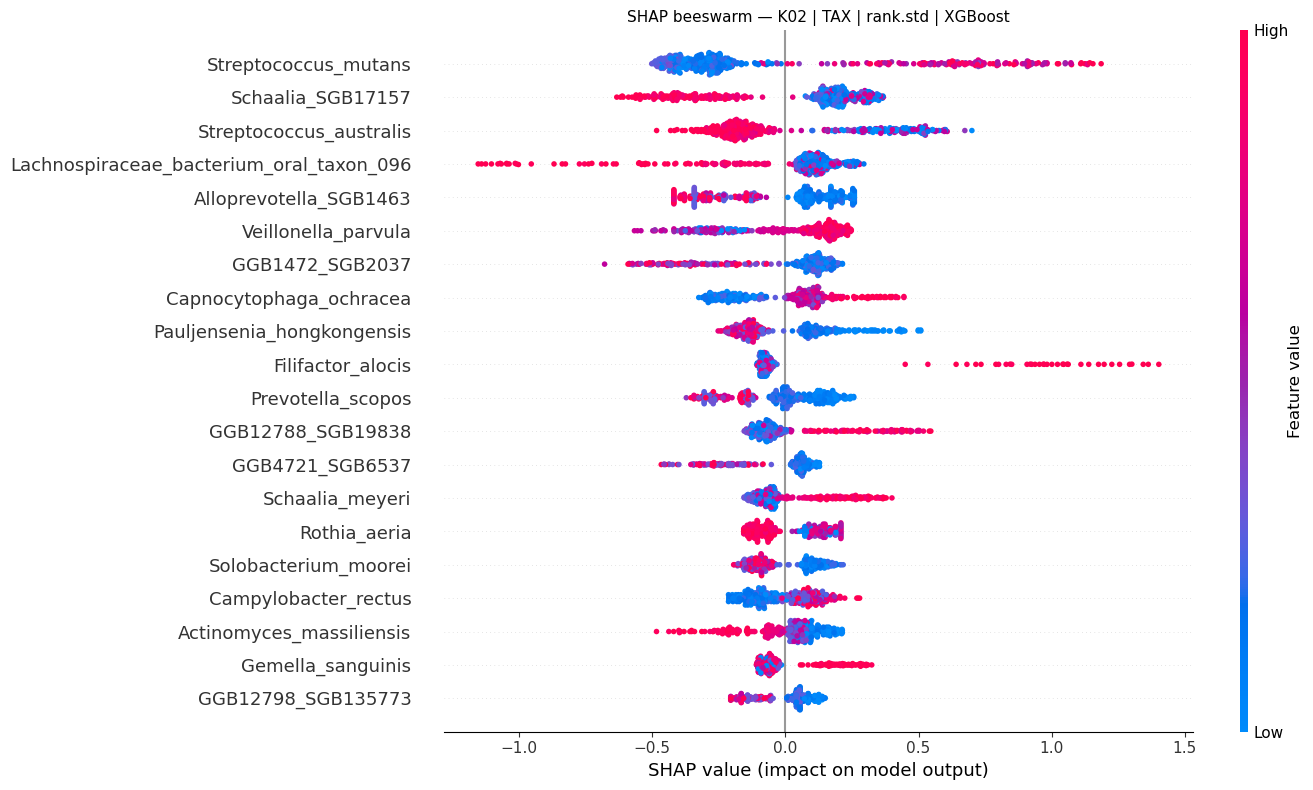


SHAP: K02 | TAX+PATH | CLR | RF


/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter

  SHAP model best params: {'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 300}


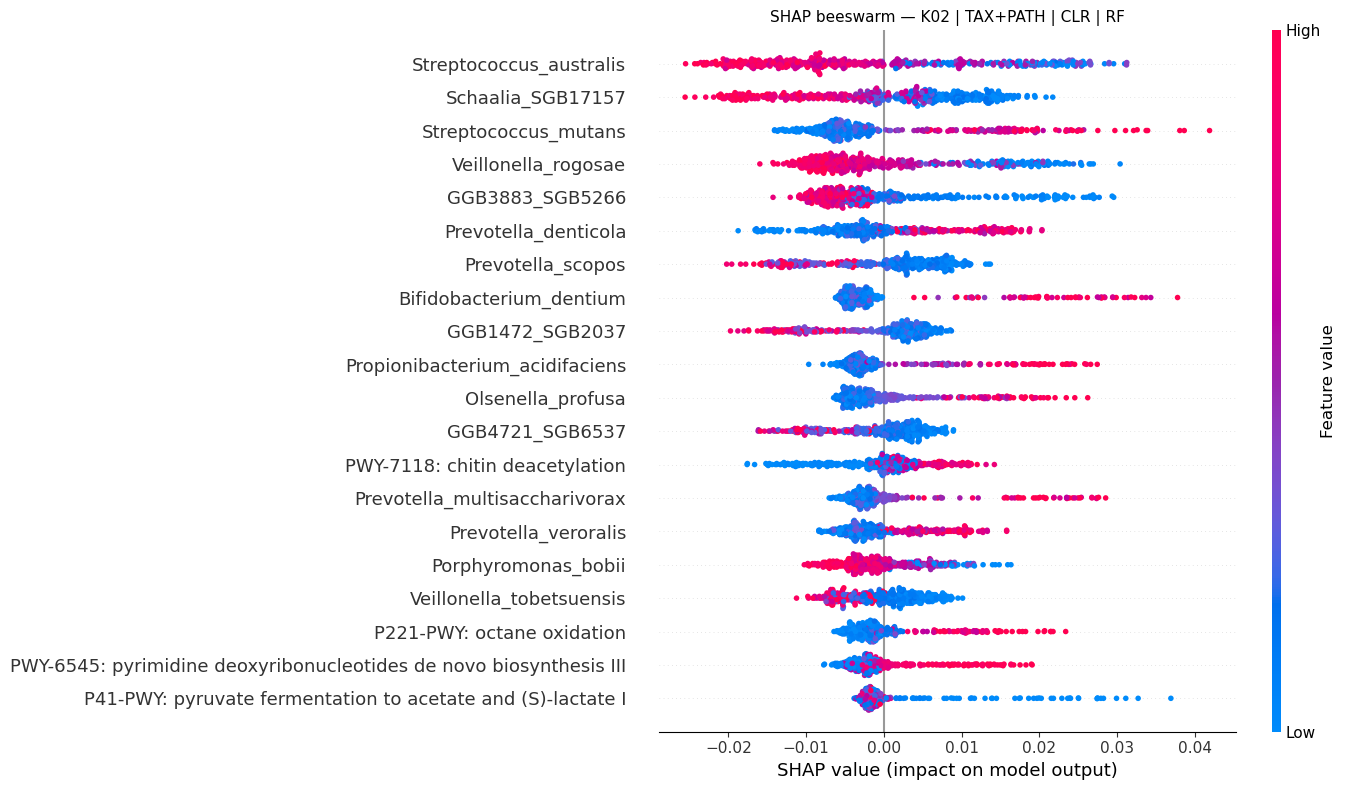


SHAP: K02 | PATH | CLR | RF


/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter

  SHAP model best params: {'max_depth': None, 'max_features': 0.3, 'n_estimators': 500}


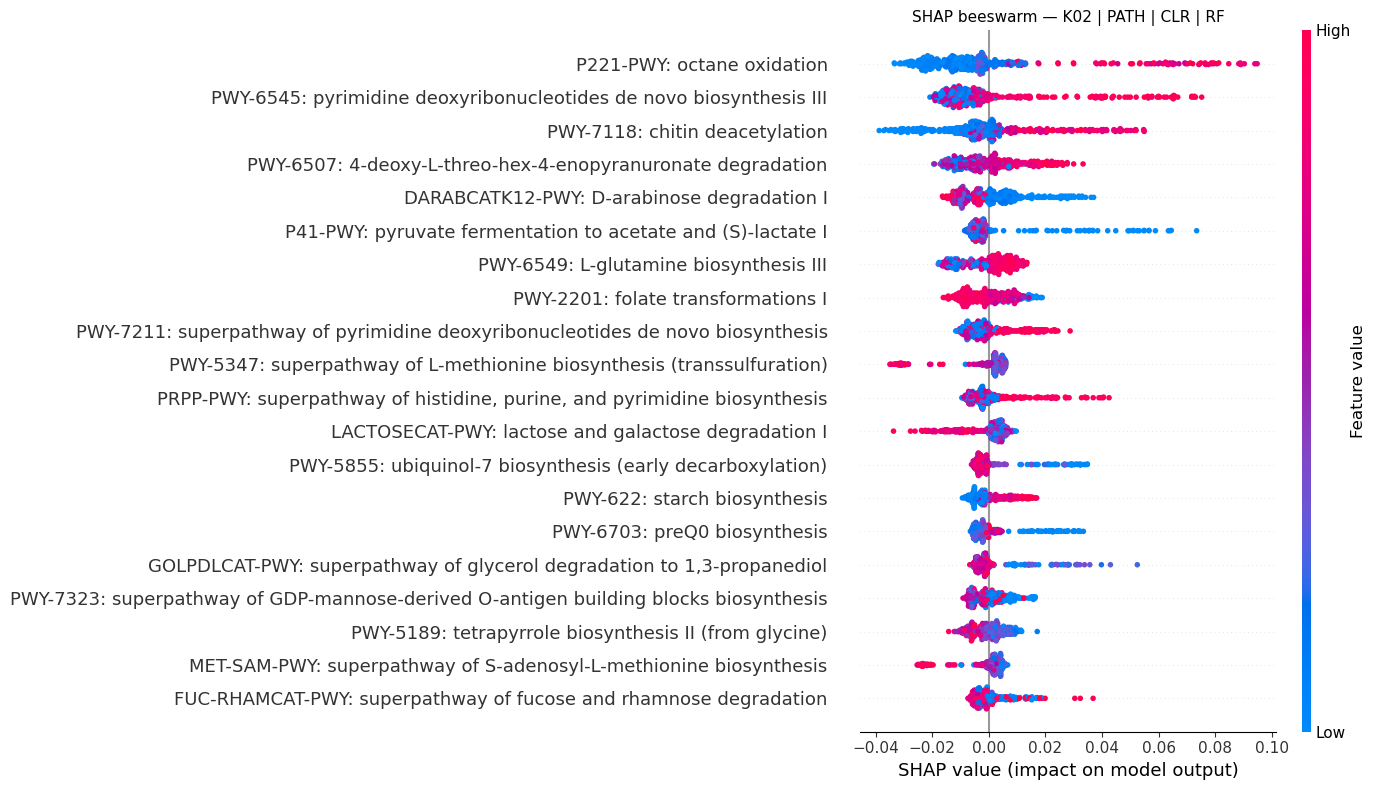

In [7]:
for r in all_results:
    task        = r['task']
    feature_set = r['feature_set']
    transform   = r['transform']
    model_name  = r['model']
    cfg_name    = r['cfg_name']

    print(f'\nSHAP: {cfg_name}')

    y          = r['y']
    is_disease = y.astype(bool)
    train_mask = is_disease | healthy

    X_tax_tr_raw  = X_tax_raw[train_mask]
    X_path_tr_raw = X_path_raw[train_mask]
    y_tr          = y[train_mask]
    bp_tr         = bioproject[train_mask]

    keep_tax  = prevalence_bioproject_filter(X_tax_tr_raw,  bp_tr)
    keep_path = prevalence_bioproject_filter(X_path_tr_raw, bp_tr)

    tax_names_f  = [tax_cols[i]  for i in range(len(tax_cols))  if keep_tax[i]]
    path_names_f = [path_cols[i] for i in range(len(path_cols)) if keep_path[i]]

    X_tax_f  = X_tax_tr_raw[:, keep_tax]
    X_path_f = X_path_tr_raw[:, keep_path]
    n_tax_f  = X_tax_f.shape[1]

    if feature_set == 'TAX':
        X_raw_f     = X_tax_f
        feat_names  = tax_names_f
    elif feature_set == 'PATH':
        X_raw_f     = X_path_f
        feat_names  = path_names_f
    else:
        X_raw_f    = np.concatenate([X_tax_f, X_path_f], axis=1)
        feat_names = tax_names_f + path_names_f

    X_t, _ = transform_fold(X_raw_f, X_raw_f, transform, feature_set, n_tax_f)

    model_shap = get_model(model_name)
    grid       = PARAM_GRIDS.get(model_name, {})
    if grid:
        inner_cv = StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
        gs = GridSearchCV(model_shap, grid, cv=inner_cv, scoring='roc_auc', refit=True, n_jobs=-1)
        gs.fit(X_t, y_tr)
        fitted_model = gs.best_estimator_
        print(f'  SHAP model best params: {gs.best_params_}')
    else:
        model_shap.fit(X_t, y_tr)
        fitted_model = model_shap

    if model_name == 'LR_Ridge':
        explainer = shap.LinearExplainer(fitted_model, X_t)
        shap_vals = explainer.shap_values(X_t)
    else:
        explainer = shap.TreeExplainer(fitted_model)
        sv = explainer.shap_values(X_t)
        if isinstance(sv, list):
            shap_vals = sv[1]
        else:
            shap_vals = np.array(sv)
            if shap_vals.ndim == 3:
                shap_vals = shap_vals[:, :, 1]

    feat_names_arr = np.array(feat_names)
    mean_abs_shap  = np.abs(shap_vals).mean(axis=0).ravel()
    top_idx        = np.argsort(mean_abs_shap)[::-1][:20]

    shap_exp = shap.Explanation(
        values        = shap_vals[:, top_idx],
        data          = X_t[:, top_idx],
        feature_names = feat_names_arr[top_idx].tolist(),
    )

    shap.plots.beeswarm(shap_exp, max_display=20, show=False, plot_size=(14, 8))
    plt.title(f'SHAP beeswarm — {cfg_name}', fontsize=11)
    plt.tight_layout()
    safe_name = cfg_name.replace(' ', '_').replace('|', '').replace('+', 'plus')
    plt.savefig(os.path.join(OUTPUT_DIR, f'shap_{safe_name}.png'), dpi=150, bbox_inches='tight')
    plt.show()